In [1]:
import torch

print("Versi PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
else:
    print("Kita menggunakan CPU")

Versi PyTorch: 2.14.1+cpu
GPU tersedia: False
Kita menggunakan CPU


In [2]:
!pip install --no-deps facenet-pytorch==2.6.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 18.8 MB/s  0:00:00


In [3]:
!pip install --no-deps retina-face


In [5]:
import torch
import cv2
import numpy as np
import tensorflow as tf

from facenet_pytorch import MTCNN
from retinaface import RetinaFace

print("PyTorch    : OK")
print("OpenCV     : OK")
print("NumPy      : OK")
print("TensorFlow : OK")
print("MTCNN      : OK")
print("RetinaFace : OK")

print("\nSEMUA LIBRARY BERHASIL DIMUAT!")

PyTorch    : OK
OpenCV     : OK
NumPy      : OK
TensorFlow : OK
MTCNN      : OK
RetinaFace : OK

SEMUA LIBRARY BERHASIL DIMUAT!


In [6]:
import torch
import cv2
import numpy as np
import tensorflow as tf

from facenet_pytorch import MTCNN
from retinaface import RetinaFace

print("================================")
print("PENGECEKAN LIBRARY")
print("================================")

print("PyTorch       :", torch.__version__)
print("CUDA          :", torch.cuda.is_available())
print("OpenCV        :", cv2.__version__)
print("NumPy         :", np.__version__)
print("TensorFlow    :", tf.__version__)

print("MTCNN         : BERHASIL")
print("RetinaFace    : BERHASIL")

print("================================")
print("SEMUA LIBRARY BERHASIL DIIMPORT")
print("================================")

PENGECEKAN LIBRARY
PyTorch       : 2.14.1+cu130
CUDA          : True
OpenCV        : 4.14.0
NumPy         : 2.4.6
TensorFlow    : 2.21.0
MTCNN         : BERHASIL
RetinaFace    : BERHASIL
SEMUA LIBRARY BERHASIL DIIMPORT


In [7]:
import torch

print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("Memory GPU:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

GPU tersedia: True
Nama GPU: Tesla T4
CUDA Version: 13.0
Memory GPU: 14.56 GB


In [8]:
import torch
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from facenet_pytorch import MTCNN

# Menggunakan GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("Device:", device)

# Inisialisasi MTCNN
mtcnn = MTCNN(
    image_size=160,
    margin=20,
    min_face_size=20,
    thresholds=[0.6, 0.7, 0.7],
    factor=0.709,
    post_process=True,
    device=device
)

print("MTCNN berhasil diinisialisasi!")

Device: cuda
MTCNN berhasil diinisialisasi!


In [9]:
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Gambar berhasil diunggah:", image_path)

Saving WhatsApp Image 2026-08-29 at 12.12.39.jpeg to WhatsApp Image 2026-08-29 at 12.12.39.jpeg
Gambar berhasil diunggah: WhatsApp Image 2026-08-29 at 12.12.39.jpeg


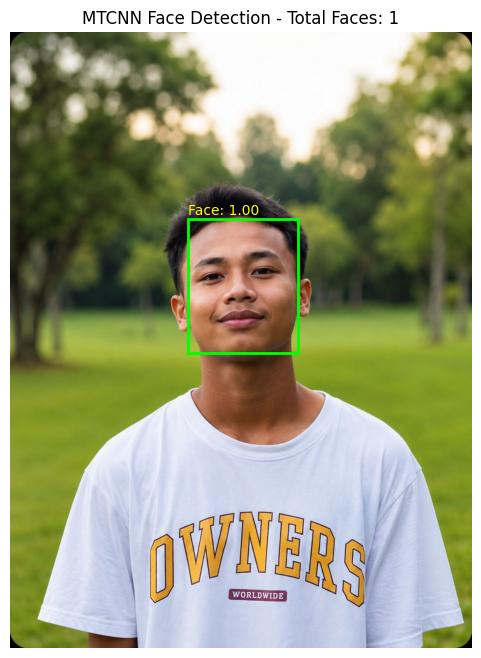

Total wajah terdeteksi: 1


In [10]:
from PIL import Image
import matplotlib.pyplot as plt

# Membaca gambar
image = Image.open(image_path).convert("RGB")

# Melakukan deteksi wajah
boxes, probs, landmarks = mtcnn.detect(
    image,
    landmarks=True
)

# Menampilkan hasil
plt.figure(figsize=(14, 8))
plt.imshow(image)

total_faces = 0

if boxes is not None:
    for box, prob in zip(boxes, probs):

        if prob is not None:
            x1, y1, x2, y2 = box.astype(int)

            plt.gca().add_patch(
                plt.Rectangle(
                    (x1, y1),
                    x2-x1,
                    y2-y1,
                    fill=False,
                    edgecolor="lime",
                    linewidth=2
                )
            )

            plt.text(
                x1,
                y1-10,
                f"Face: {prob:.2f}",
                color="yellow",
                fontsize=10
            )

            total_faces += 1

plt.title(f"MTCNN Face Detection - Total Faces: {total_faces}")
plt.axis("off")
plt.show()

print("Total wajah terdeteksi:", total_faces)

In [12]:
!pip install tf-keras==2.21.0

In [13]:
import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import tensorflow as tf
import torch
import cv2
import numpy as np

from retinaface import RetinaFace
from facenet_pytorch import MTCNN
from PIL import Image

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

print("RetinaFace:", "READY")
print("MTCNN:", "READY")

TensorFlow: 2.21.0
PyTorch: 2.14.1+cu130
GPU tersedia: True
RetinaFace: READY
MTCNN: READY


In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mtcnn = MTCNN(
    image_size=160,
    margin=20,
    min_face_size=20,
    thresholds=[0.6, 0.7, 0.7],
    factor=0.709,
    post_process=True,
    device=device
)

print("MTCNN berhasil diinisialisasi!")

MTCNN berhasil diinisialisasi!


In [17]:
from google.colab import files

uploaded = files.upload()
image_path = list(uploaded.keys())[0]

print("Gambar:", image_path)

Saving WhatsApp Image 2026-08-29 at 12.12.39.jpeg to WhatsApp Image 2026-08-29 at 12.12.39 (2).jpeg
Gambar: WhatsApp Image 2026-08-29 at 12.12.39 (2).jpeg


In [19]:
import os
import sys
import tensorflow as tf
import tf_keras

print("========== DIAGNOSTIK RETINAFACE ==========")

print("TensorFlow Version :", tf.__version__)
print("TF_USE_LEGACY_KERAS:", os.environ.get("TF_USE_LEGACY_KERAS"))

print("TensorFlow Keras   :", tf.keras.__file__)
print("Legacy Keras       :", tf_keras.__file__)

print("Keras 3 terimport  :", "keras" in sys.modules)
print("===========================================")

========== DIAGNOSTIK RETINAFACE ==========
TensorFlow Version : 2.21.0
TF_USE_LEGACY_KERAS: 1
TensorFlow Keras   : /usr/local/lib/python3.13/dist-packages/keras/_tf_keras/keras/__init__.py
Legacy Keras       : /usr/local/lib/python3.13/dist-packages/tf_keras/__init__.py
Keras 3 terimport  : True


In [20]:
import tensorflow as tf
import tf_keras

print("========== CEK BACKEND KERAS ==========")
print("TensorFlow Keras Name :", tf.keras.__name__)
print("TensorFlow Keras File :", tf.keras.__file__)
print("TensorFlow Keras Layer:", tf.keras.layers.Layer.__module__)
print("Legacy Keras Version  :", tf_keras.__version__)
print("Legacy Keras Layer    :", tf_keras.layers.Layer.__module__)
print("======================================")

========== CEK BACKEND KERAS ==========
TensorFlow Keras Name : tensorflow.keras
TensorFlow Keras File : /usr/local/lib/python3.13/dist-packages/keras/_tf_keras/keras/__init__.py
TensorFlow Keras Layer: keras.src.layers.layer
Legacy Keras Version  : 2.21.0
Legacy Keras Layer    : tf_keras.src.engine.base_layer


In [21]:

# ==========================================
# KONFIGURASI ENVIRONMENT CCTV FACE DETECTION
# ==========================================

import os

# Wajib diatur sebelum import TensorFlow
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import torch
import tensorflow as tf
import tf_keras
import cv2
import numpy as np

from retinaface import RetinaFace
from facenet_pytorch import MTCNN

print("========== CEK ENVIRONMENT ==========")
print("TensorFlow :", tf.__version__)
print("TF-Keras   :", tf_keras.__version__)
print("PyTorch    :", torch.__version__)
print("OpenCV     :", cv2.__version__)
print("GPU        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name   :", torch.cuda.get_device_name(0))

print("RetinaFace : READY")
print("MTCNN      : READY")
print("=====================================")


========== CEK ENVIRONMENT ==========
TensorFlow : 2.21.0
TF-Keras   : 2.21.0
PyTorch    : 2.14.1+cu130
OpenCV     : 4.14.0
GPU        : True
GPU Name   : Tesla T4
RetinaFace : READY
MTCNN      : READY


In [26]:

!pip uninstall -y retina-face
!pip install -U "retina-face[pytorch]"


Found existing installation: retina-face 0.0.19
Uninstalling retina-face-0.0.19:
  Successfully uninstalled retina-face-0.0.19
  Using cached retina_face-0.0.19-py3-none-any.whl.metadata (9.6 kB)
Using cached retina_face-0.0.19-py3-none-any.whl (33 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 47.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 56.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [retina-face]


In [27]:

import torch
import sys
import importlib.metadata as metadata

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("RetinaFace:", metadata.version("retina-face"))
print("GPU:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
RetinaFace: 0.0.19
GPU: True


In [1]:

import os

os.environ["DEEPFACE_BACKEND_ENGINE"] = "pytorch"

from retinaface.commons import backend_utils

print("TensorFlow backend:", backend_utils.is_tensorflow())


TensorFlow backend: False


In [2]:
import inspect
from retinaface.commons import backend_utils

print(inspect.getsource(backend_utils.is_tensorflow))

def is_tensorflow() -> bool:
    """
    Check if retinaface runs on tensorflow
    Returns:
        result (bool)
    """
    return get_backend_engine() == TENSORFLOW



In [3]:
from retinaface.commons import backend_utils

print("Backend aktif:", backend_utils.get_backend_engine())
print("TensorFlow:", backend_utils.TENSORFLOW)

Backend aktif: pytorch
TensorFlow: tensorflow


In [4]:
from retinaface import RetinaFace

print("RetinaFace berhasil di-import!")

RetinaFace berhasil di-import!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving WhatsApp Image 2026-08-29 at 12.12.39.jpeg to WhatsApp Image 2026-08-29 at 12.12.39 (3).jpeg


In [7]:
image_path = next(iter(uploaded.keys()))

print("Lokasi gambar:", image_path)

Lokasi gambar: WhatsApp Image 2026-08-29 at 12.12.39 (3).jpeg


In [8]:
faces = RetinaFace.detect_faces(image_path)

print(faces)

26-11-13 17:28:29 - Directory /root/.deepface/weights created
26-11-13 17:28:29 - retinaface.pth will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.pth


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.pth
To: /root/.deepface/weights/retinaface.pth
100%|██████████| 118M/118M [00:02<00:00, 52.4MB/s]


{'face_1': {'score': np.float64(0.9995309114456177), 'facial_area': [np.int64(408), np.int64(434), np.int64(672), np.int64(761)], 'landmarks': {'right_eye': [np.float32(476.1122), np.float32(573.1488)], 'left_eye': [np.float32(596.7128), np.float32(563.7724)], 'nose': [np.float32(537.2966), np.float32(614.20264)], 'mouth_right': [np.float32(488.21085), np.float32(677.55646)], 'mouth_left': [np.float32(595.82104), np.float32(670.41986)]}}}


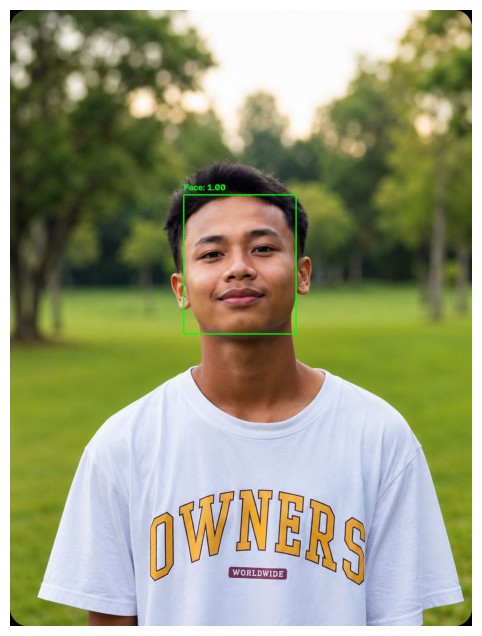

In [9]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

for key, face in faces.items():
    x1, y1, x2, y2 = face["facial_area"]

    cv2.rectangle(
        img,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        2
    )

    cv2.putText(
        img,
        f"Face: {float(face['score']):.2f}",
        (int(x1), int(y1) - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [10]:
!mkdir -p /content/FDDB
%cd /content/FDDB

!wget https://vis-www.cs.umass.edu/fddb/FDDB-folds.tgz
!wget https://tamaraberg.com/faceDataset/originalPics.tar.gz

/content/FDDB
--2026-11-13 17:31:18--  https://vis-www.cs.umass.edu/fddb/FDDB-folds.tgz
Resolving vis-www.cs.umass.edu (vis-www.cs.umass.edu)... failed: Name or service not known.
wget: unable to resolve host address ‘vis-www.cs.umass.edu’
--2026-11-13 17:31:19--  https://tamaraberg.com/faceDataset/originalPics.tar.gz
Resolving tamaraberg.com (tamaraberg.com)... 3.94.187.137
Connecting to tamaraberg.com (tamaraberg.com)|3.94.187.137|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-13 17:31:19 ERROR 404: Not Found.



In [11]:
!tar -xzf FDDB-folds.tgz
!mkdir -p images
!tar -xzf originalPics.tar.gz -C images

tar (child): FDDB-folds.tgz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now
tar (child): originalPics.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now


In [12]:
%cd /content/FDDB

!wget -c http://vis-www.cs.umass.edu/fddb/FDDB-folds.tgz
!wget -c http://tamaraberg.com/faceDataset/originalPics.tar.gz

/content/FDDB
--2026-11-13 17:32:28--  http://vis-www.cs.umass.edu/fddb/FDDB-folds.tgz
Resolving vis-www.cs.umass.edu (vis-www.cs.umass.edu)... failed: Name or service not known.
wget: unable to resolve host address ‘vis-www.cs.umass.edu’
--2026-11-13 17:32:28--  http://tamaraberg.com/faceDataset/originalPics.tar.gz
Resolving tamaraberg.com (tamaraberg.com)... 3.94.187.137
Connecting to tamaraberg.com (tamaraberg.com)|3.94.187.137|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://tamaraberg.com/faceDataset/originalPics.tar.gz [following]
--2026-11-13 17:32:28--  https://tamaraberg.com/faceDataset/originalPics.tar.gz
Connecting to tamaraberg.com (tamaraberg.com)|3.94.187.137|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-13 17:32:28 ERROR 404: Not Found.



In [13]:
!ls -lh /content/FDDB

total 4.0K
drwxr-xr-x 2 root root 4.0K Nov 13 17:31 images


In [14]:
import requests

urls = [
    "https://vis-www.cs.umass.edu/fddb/FDDB-folds.tgz",
    "https://tamaraberg.com/faceDataset/originalPics.tar.gz"
]

for url in urls:
    try:
        response = requests.get(url, stream=True, timeout=30)
        print("URL:", url)
        print("Status:", response.status_code)
        print("Content-Type:", response.headers.get("Content-Type"))
        print("Ukuran:", response.headers.get("Content-Length"))
        print("-" * 50)
    except Exception as e:
        print("Gagal:", e)

Gagal: HTTPSConnectionPool(host='vis-www.cs.umass.edu', port=443): Max retries exceeded with url: /fddb/FDDB-folds.tgz (Caused by NameResolutionError("<urllib3.connection.HTTPSConnection object at 0x7c5c6373ead0>: Failed to resolve 'vis-www.cs.umass.edu' ([Errno -2] Name or service not known)"))
URL: https://tamaraberg.com/faceDataset/originalPics.tar.gz
Status: 404
Content-Type: text/html; charset=iso-8859-1
Ukuran: 277
--------------------------------------------------


In [15]:
import requests

url = "https://github.com/imistyrain/fddb"

r = requests.get(url)

print("Status:", r.status_code)
print("GitHub dapat diakses:", r.status_code == 200)

Status: 200
GitHub dapat diakses: True


In [16]:
import requests

url = "https://api.github.com/repos/imistyrain/fddb/contents"

response = requests.get(url)
data = response.json()

for item in data:
    print(item["name"], "-", item["type"])

.gitignore - file
FDDB-folds - dir
README.txt - file
Readme.md - file
compareROC - dir
evaluation - dir
mrconfig.xml - file
outputs - dir
show_gt.py - file


In [17]:
import requests

folders = ["FDDB-folds", "outputs", "evaluation"]

for folder in folders:
    url = f"https://api.github.com/repos/imistyrain/fddb/contents/{folder}"
    response = requests.get(url)

    print(f"\n===== {folder} =====")

    if response.status_code == 200:
        for item in response.json():
            print(item["name"], "-", item["type"])
    else:
        print("Gagal membaca folder:", response.status_code)


===== FDDB-folds =====
FDDB-fold-01-ellipseList.txt - file
FDDB-fold-01.txt - file
FDDB-fold-02-ellipseList.txt - file
FDDB-fold-02.txt - file
FDDB-fold-03-ellipseList.txt - file
FDDB-fold-03.txt - file
FDDB-fold-04-ellipseList.txt - file
FDDB-fold-04.txt - file
FDDB-fold-05-ellipseList.txt - file
FDDB-fold-05.txt - file
FDDB-fold-06-ellipseList.txt - file
FDDB-fold-06.txt - file
FDDB-fold-07-ellipseList.txt - file
FDDB-fold-07.txt - file
FDDB-fold-08-ellipseList.txt - file
FDDB-fold-08.txt - file
FDDB-fold-09-ellipseList.txt - file
FDDB-fold-09.txt - file
FDDB-fold-10-ellipseList.txt - file
FDDB-fold-10.txt - file

===== outputs =====
JDA - dir
MTCNN - dir
MTCNNContROC.png - file
MTCNNContROC.txt - file
MTCNNDiscROC.png - file
MTCNNDiscROC.txt - file
jfda - dir
jfdaContROC.png - file
jfdaContROC.txt - file
jfdaDiscROC.png - file
jfdaDiscROC.txt - file
pyface - dir
pyfaceContROC.p - file
pyfaceContROC.png - file
pyfaceContROC.txt - file
pyfaceDiscROC.png - file
pyfaceDiscROC.txt - fil

In [18]:
%cd /content/FDDB

!git clone https://github.com/imistyrain/fddb.git repository

/content/FDDB
Cloning into 'repository'...
remote: Enumerating objects: 226, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 226 (delta 1), reused 6 (delta 1), pack-reused 217 (from 1)
Receiving objects: 100% (226/226), 1.84 MiB | 5.03 MiB/s, done.
Resolving deltas: 100% (66/66), done.


In [20]:
!cp -r repository/FDDB-folds ./FDDB-folds

In [21]:
import requests

url = "https://tamaraberg.com/faceDataset/"

try:
    response = requests.get(url, timeout=30)
    print("Status:", response.status_code)
    print("URL akhir:", response.url)
    print(response.text[:500])
except Exception as e:
    print("Error:", e)

Status: 404
URL akhir: https://tamaraberg.com/faceDataset/
<!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//EN">
<html><head>
<title>404 Not Found</title>
</head><body>
<h1>Not Found</h1>
<p>The requested URL was not found on this server.</p>
<hr>
<address>Apache/2.4.41 (Ubuntu) Server at tamaraberg.com Port 443</address>
</body></html>



In [22]:
import requests

url = "https://hyper.ai/en/datasets/5280"

r = requests.get(url, timeout=30)

print("Status:", r.status_code)
print("URL:", r.url)
print("Berhasil diakses:", r.status_code == 200)

Status: 200
URL: https://hyper.ai/en/datasets/5280
Berhasil diakses: True


In [26]:
import requests
from bs4 import BeautifulSoup

url = "https://hyper.ai/en/datasets/5280"
response = requests.get(url)

soup = BeautifulSoup(response.text, "html.parser")

for link in soup.find_all("a", href=True):
    href = link["href"]
    text = link.get_text(" ", strip=True)

    if "FDDB" in text or "originalPics" in text or "FDDB" in href:
        print("Nama:", text)
        print("Link:", href)
        print("-" * 50)

In [27]:
import requests

url = "https://hyper.ai/en/datasets/5280"
r = requests.get(url)

for keyword in ["torrent", "originalPics", "FDDB-folds", "download"]:
    print(f"\nPencarian: {keyword}")
    print("Ditemukan:", keyword.lower() in r.text.lower())


Pencarian: torrent
Ditemukan: True

Pencarian: originalPics
Ditemukan: True

Pencarian: FDDB-folds
Ditemukan: True

Pencarian: download
Ditemukan: True


In [28]:
import requests
import re

url = "https://hyper.ai/en/datasets/5280"
html = requests.get(url, timeout=30).text

# Cari alamat unduhan yang mengandung kata torrent
links = re.findall(r'https?[^"\'\s<>]+', html)

hasil = [link.replace("&amp;", "&") for link in links
         if "torrent" in link.lower() or "download" in link.lower()]

for link in sorted(set(hasil)):
    print(link)

https://orion.hyper.ai/tracker/download?torrent=6419\
https://orion.hyper.ai/tracker/magnet?torrent=6419\


In [29]:
import requests

url = "https://orion.hyper.ai/tracker/download?torrent=6419"

r = requests.get(url, timeout=60)

print("Status:", r.status_code)
print("Ukuran:", len(r.content), "bytes")
print("Tipe file:", r.headers.get("content-type"))

if r.status_code == 200 and len(r.content) > 0:
    with open("/content/FDDB.torrent", "wb") as f:
        f.write(r.content)
    print("File torrent berhasil disimpan!")
else:
    print("File torrent belum berhasil diunduh.")

Status: 200
Ukuran: 6646 bytes
Tipe file: application/x-bittorrent
File torrent berhasil disimpan!


In [30]:
!apt-get -qq install aria2
!aria2c --show-files /content/FDDB.torrent

Selecting previously unselected package libcares2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libcares2_1.27.0-1.0ubuntu1_amd64.deb ...
Unpacking libcares2:amd64 (1.27.0-1.0ubuntu1) ...
Selecting previously unselected package libaria2-0:amd64.
Preparing to unpack .../libaria2-0_1.37.0+debian-1build3_amd64.deb ...
Unpacking libaria2-0:amd64 (1.37.0+debian-1build3) ...
Selecting previously unselected package aria2.
Preparing to unpack .../aria2_1.37.0+debian-1build3_amd64.deb ...
Unpacking aria2 (1.37.0+debian-1build3) ...
Setting up libcares2:amd64 (1.27.0-1.0ubuntu1) ...
Setting up libaria2-0:amd64 (1.37.0+debian-1build3) ...
Setting up aria2 (1.37.0+debian-1build3) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/

In [32]:
!aria2c \
  --seed-time=0 \
  --dir=/content \
  --select-file=1-8 \
  /content/FDDB.torrent


11/13 17:44:19 [NOTICE] Downloading 1 item(s)

11/13 17:44:19 [NOTICE] IPv4 DHT: listening on UDP port 6886

11/13 17:44:19 [NOTICE] IPv4 BitTorrent: listening on TCP port 6929

11/13 17:44:19 [ERROR] IPv6 BitTorrent: failed to bind TCP port 6929
Exception: [SocketCore.cc:312] errorCode=1 Failed to bind a socket, cause: Name or service not known

11/13 17:44:20 [NOTICE] CUID#20 - Redirecting to https://orion.hyper.ai/tracker/announce?info_hash=%80%BE%FD%22%06D%AB%FA%E2%98%B1%A8%89%F3%F8L%F3%8F%EA%28&peer_id=A2-1-37-0-%82%86%B8%D2%A6%EDAY%2C%29&uploaded=0&downloaded=0&left=572349206&compact=1&key=%B8%D2%A6%EDAY%2C%29&numwant=50&no_peer_id=1&port=6929&event=started&supportcrypto=1
 *** Download Progress Summary as of Fri Nov 13 17:45:20 2026 *** 
=
[#3a95c8 43MiB/552MiB(7%) CN:3 SD:1 DL:659KiB ETA:13m10s]
FILE: /content/FDDB/README.md (7more)
-

 *** Download Progress Summary as of Fri Nov 13 17:46:21 2026 *** 
=
[#3a95c8 83MiB/552MiB(15%) CN:1 SD:1 DL:782KiB ETA:10m14s]
FILE: /content/

In [35]:
!ls -lh /content/FDDB/data/

total 553M
-rw-r--r-- 1 root root 157K Nov 13 17:48 FDDB-folds.tgz
-rw-r--r-- 1 root root 553M Nov 13 17:48 originalPics.tar.gz
-rw-r--r-- 1 root root 2.5K Nov 13 17:48 README.txt


In [36]:
!ls /content/FDDB/annotations/

FDDB-folds


In [37]:
!ls -lh /content/FDDB/annotations/FDDB-folds/

total 440K
-rw-r--r-- 1 1054 505  35K Mar 31  2010 FDDB-fold-01-ellipseList.txt
-rw-r--r-- 1 1054 505 6.6K Feb  6  2010 FDDB-fold-01.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-02-ellipseList.txt
-rw-r--r-- 1 1054 505 6.5K Feb  6  2010 FDDB-fold-02.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-03-ellipseList.txt
-rw-r--r-- 1 1054 505 6.3K Feb  6  2010 FDDB-fold-03.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-04-ellipseList.txt
-rw-r--r-- 1 1054 505 6.9K Feb  6  2010 FDDB-fold-04.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-05-ellipseList.txt
-rw-r--r-- 1 1054 505 6.8K Feb  6  2010 FDDB-fold-05.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-06-ellipseList.txt
-rw-r--r-- 1 1054 505 6.9K Feb  6  2010 FDDB-fold-06.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-07-ellipseList.txt
-rw-r--r-- 1 1054 505 6.4K Feb  6  2010 FDDB-fold-07.txt
-rw-r--r-- 1 1054 505  35K Feb  6  2010 FDDB-fold-08-ellipseList.txt
-rw-r--r-- 1 1054 505 6.4K Feb  6  201

In [38]:
!tar -xzf /content/FDDB/data/originalPics.tar.gz -C /content/FDDB/

In [39]:
!find /content/FDDB/originalPics -type f | wc -l

find: ‘/content/FDDB/originalPics’: No such file or directory
0


In [40]:
!ls -lah /content/FDDB/

total 184K
drwxr-xr-x  9 root root 4.0K Nov 13 17:51 .
drwxr-xr-x  1 root root 4.0K Nov 13 17:48 ..
drwxr-xr-x  8 root root 4.0K Nov 13 17:51 2002
drwxr-xr-x 11 root root 4.0K Nov 13 17:51 2003
drwxr-xr-x  3 root root 4.0K Nov 13 17:49 annotations
drwxr-xr-x  2 root root 4.0K Nov 13 17:43 data
drwxr-xr-x  3 root root 4.0K Nov 13 17:36 FDDB-folds
drwxr-xr-x  2 root root 4.0K Nov 13 17:31 images
-rw-r--r--  1 root root 1.2K Nov 13 17:48 README.md
-rw-r--r--  1 root root 1.2K Nov 13 17:48 README.txt
drwxr-xr-x  7 root root 4.0K Nov 13 17:35 repository
-rw-r--r--  1 root root  38K Nov 13 17:45 samples_0.jpg
-rw-r--r--  1 root root  46K Nov 13 17:45 samples_1.jpg
-rw-r--r--  1 root root  50K Nov 13 17:45 samples_2.jpg


In [41]:
!tar -tzf /content/FDDB/data/originalPics.tar.gz | head -20

2002/09/28/big/img_828.jpg
2002/07/25/big/img_844.jpg
2002/10/23/big/img_318.jpg
2002/10/03/big/img_2009.jpg
2003/07/31/big/img_1217.jpg
2002/07/25/big/img_491.jpg
2003/06/13/big/img_995.jpg
2003/06/21/big/img_11.jpg
2002/12/22/big/img_70.jpg
2003/08/20/big/img_486.jpg
2003/01/19/big/img_592.jpg
2002/08/31/big/img_17919.jpg
2003/01/21/big/img_192.jpg
2003/06/04/big/img_1122.jpg
2002/10/10/big/img_375.jpg
2003/03/07/big/img_1119.jpg
2003/07/25/big/img_403.jpg
2003/08/28/big/img_636.jpg
2003/04/28/big/img_822.jpg
2002/10/28/big/img_137.jpg


In [42]:
import os

image_count = 0

for root, dirs, files in os.walk("/content/FDDB"):
    image_count += sum(
        1 for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))
    )

print("Total gambar:", image_count)

Total gambar: 28220


In [43]:
import os

base = "/content/FDDB"

total = 0

for tahun in ["2002", "2003"]:
    folder = os.path.join(base, tahun)
    jumlah = 0

    for root, dirs, files in os.walk(folder):
        jumlah += sum(
            1 for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )

    print(f"Gambar tahun {tahun}: {jumlah}")
    total += jumlah

print("Total gambar FDDB:", total)

Gambar tahun 2002: 12620
Gambar tahun 2003: 15584
Total gambar FDDB: 28204


In [44]:
annotation_file = "/content/FDDB/annotations/FDDB-folds/FDDB-fold-01.txt"

with open(annotation_file, "r") as f:
    daftar = [line.strip() for line in f if line.strip()]

print("Jumlah gambar dalam Fold 01:", len(daftar))
print("\nContoh 5 nama gambar:")
for nama in daftar[:5]:
    print(nama)

Jumlah gambar dalam Fold 01: 290

Contoh 5 nama gambar:
2002/08/11/big/img_591
2002/08/26/big/img_265
2002/07/19/big/img_423
2002/08/24/big/img_490
2002/08/31/big/img_17676


In [45]:
base = "/content/FDDB/annotations/FDDB-folds"

total = 0

for i in range(1, 11):
    file_path = f"{base}/FDDB-fold-{i:02d}.txt"

    with open(file_path, "r") as f:
        jumlah = sum(1 for line in f if line.strip())

    print(f"Fold {i:02d}: {jumlah} gambar")
    total += jumlah

print("\nTotal seluruh fold:", total)

Fold 01: 290 gambar
Fold 02: 285 gambar
Fold 03: 274 gambar
Fold 04: 302 gambar
Fold 05: 298 gambar
Fold 06: 302 gambar
Fold 07: 279 gambar
Fold 08: 276 gambar
Fold 09: 259 gambar
Fold 10: 280 gambar

Total seluruh fold: 2845


In [46]:
import os

base = "/content/FDDB"
annotation_base = "/content/FDDB/annotations/FDDB-folds"

total = 0
missing = []

for i in range(1, 11):
    file_path = f"{annotation_base}/FDDB-fold-{i:02d}.txt"

    with open(file_path, "r") as f:
        image_names = [line.strip() for line in f if line.strip()]

    for name in image_names:
        image_path = os.path.join(base, name + ".jpg")
        total += 1

        if not os.path.exists(image_path):
            missing.append(image_path)

print("Total gambar diperiksa:", total)
print("Gambar ditemukan:", total - len(missing))
print("Gambar tidak ditemukan:", len(missing))

if missing:
    print("\nContoh gambar yang tidak ditemukan:")
    print(*missing[:10], sep="\n")

Total gambar diperiksa: 2845
Gambar ditemukan: 2845
Gambar tidak ditemukan: 0


In [48]:
!pip install mtcnn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 14.7 MB/s  0:00:00


In [49]:
from mtcnn import MTCNN

detector = MTCNN()
print("MTCNN berhasil diinisialisasi!")

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


MTCNN berhasil diinisialisasi!


Jumlah wajah terdeteksi: 1


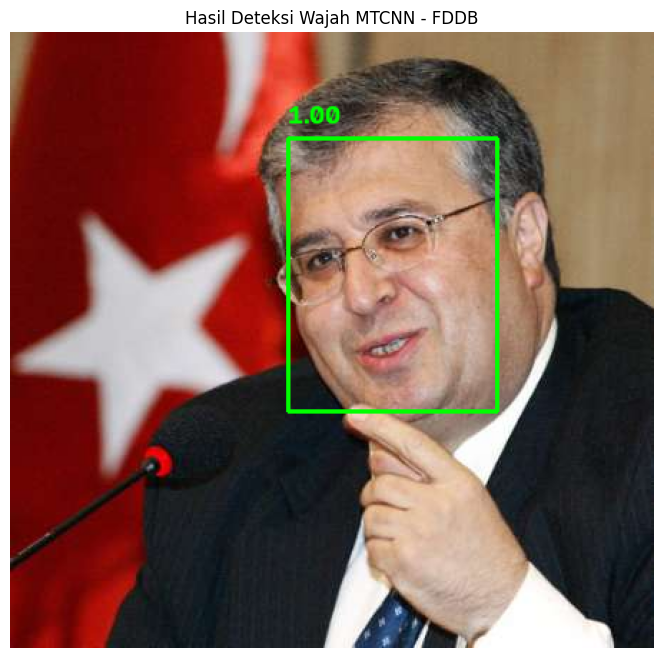

In [50]:
import cv2
import matplotlib.pyplot as plt
from mtcnn import MTCNN

# Ambil gambar FDDB
image_path = "/content/FDDB/2002/08/11/big/img_591.jpg"

# Baca gambar
image = cv2.imread(image_path)

if image is None:
    print("Gambar tidak ditemukan!")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Deteksi wajah
    results = detector.detect_faces(image_rgb)

    print("Jumlah wajah terdeteksi:", len(results))

    # Gambar bounding box
    for face in results:
        x, y, width, height = face["box"]
        confidence = face["confidence"]

        cv2.rectangle(
            image_rgb,
            (x, y),
            (x + width, y + height),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image_rgb,
            f"{confidence:.2f}",
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    plt.figure(figsize=(10, 8))
    plt.imshow(image_rgb)
    plt.axis("off")
    plt.title("Hasil Deteksi Wajah MTCNN - FDDB")
    plt.show()

Jumlah wajah terdeteksi: 1
face_1
Confidence: 0.9993984699249268
Bounding Box: [np.int64(191), np.int64(67), np.int64(347), np.int64(272)]


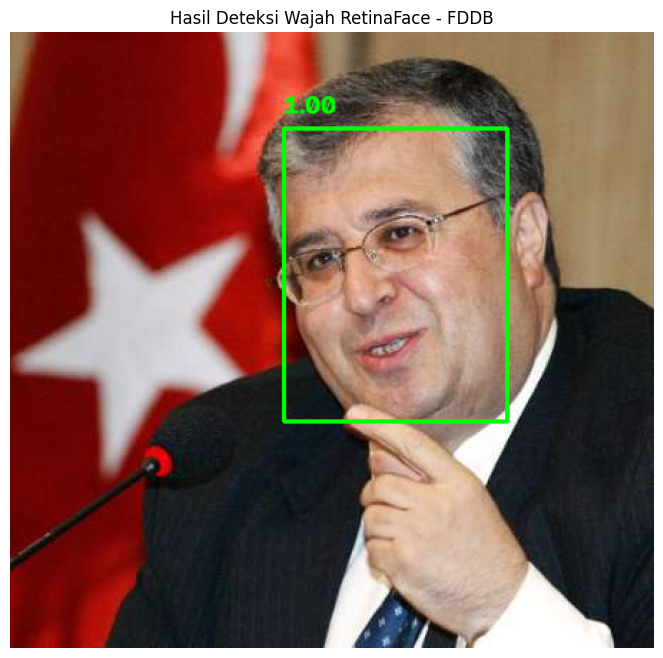

In [51]:
import cv2
import matplotlib.pyplot as plt
from retinaface import RetinaFace

# Gunakan gambar FDDB yang sama
image_path = "/content/FDDB/2002/08/11/big/img_591.jpg"

# Baca gambar asli
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Deteksi wajah menggunakan RetinaFace
results = RetinaFace.detect_faces(img_path=image_path)

# Tampilkan jumlah wajah
if isinstance(results, dict):
    print("Jumlah wajah terdeteksi:", len(results))

    for name, face in results.items():
        print(name)
        print("Confidence:", face["score"])
        print("Bounding Box:", face["facial_area"])

        x1, y1, x2, y2 = face["facial_area"]

        cv2.rectangle(
            image_rgb,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image_rgb,
            f'{face["score"]:.2f}',
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )
else:
    print("Tidak ada wajah yang terdeteksi.")
    print("Hasil:", results)

# Tampilkan gambar
plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Hasil Deteksi Wajah RetinaFace - FDDB")
plt.show()

In [52]:
import time

# Persiapan gambar
image_path = "/content/FDDB/2002/08/11/big/img_591.jpg"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Pengujian MTCNN
start = time.perf_counter()
mtcnn_results = detector.detect_faces(image_rgb)
mtcnn_time = time.perf_counter() - start

# Pengujian RetinaFace
start = time.perf_counter()
retina_results = RetinaFace.detect_faces(img_path=image_path)
retina_time = time.perf_counter() - start

# Tampilkan hasil
print("=== PERBANDINGAN WAKTU DETEKSI ===")
print(f"MTCNN     : {mtcnn_time:.4f} detik")
print(f"RetinaFace: {retina_time:.4f} detik")

=== PERBANDINGAN WAKTU DETEKSI ===
MTCNN     : 0.4587 detik
RetinaFace: 3.9213 detik


In [53]:
import time
import numpy as np

image_path = "/content/FDDB/2002/08/11/big/img_591.jpg"

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Warm-up kedua model
detector.detect_faces(image_rgb)
RetinaFace.detect_faces(img_path=image_path)

# Pengujian berulang
mtcnn_times = []
retina_times = []

for i in range(5):
    start = time.perf_counter()
    detector.detect_faces(image_rgb)
    mtcnn_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    RetinaFace.detect_faces(img_path=image_path)
    retina_times.append(time.perf_counter() - start)

# Hitung rata-rata
print("=== HASIL PENGUJIAN 5 KALI ===")
print(f"MTCNN rata-rata     : {np.mean(mtcnn_times):.4f} detik")
print(f"RetinaFace rata-rata: {np.mean(retina_times):.4f} detik")

print("\nWaktu setiap pengujian:")
print("MTCNN:", [round(x, 4) for x in mtcnn_times])
print("RetinaFace:", [round(x, 4) for x in retina_times])

=== HASIL PENGUJIAN 5 KALI ===
MTCNN rata-rata     : 0.2533 detik
RetinaFace rata-rata: 3.8906 detik

Waktu setiap pengujian:
MTCNN: [0.2467, 0.2391, 0.2495, 0.2321, 0.2993]
RetinaFace: [4.6392, 3.5156, 3.4904, 4.0474, 3.7603]


In [54]:
import os
import time
import pandas as pd
import cv2

# Lokasi dataset dan anotasi
base_dir = "/content/FDDB"
annotation_dir = "/content/FDDB/annotations/FDDB-folds"

fold_file = os.path.join(annotation_dir, "FDDB-fold-01.txt")

# Ambil 20 gambar pertama
with open(fold_file, "r") as f:
    image_names = [line.strip() for line in f if line.strip()]

image_names = image_names[:20]

results_data = []

print("Mulai pengujian 20 gambar FDDB...\n")

for index, name in enumerate(image_names, start=1):

    image_path = os.path.join(base_dir, name + ".jpg")
    image = cv2.imread(image_path)

    if image is None:
        print(f"Gambar tidak ditemukan: {name}")
        continue

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # MTCNN
    start = time.perf_counter()
    mtcnn_result = detector.detect_faces(image_rgb)
    mtcnn_time = time.perf_counter() - start

    # RetinaFace
    start = time.perf_counter()
    retina_result = RetinaFace.detect_faces(img_path=image_path)
    retina_time = time.perf_counter() - start

    # Hitung jumlah wajah RetinaFace
    retina_count = len(retina_result) if isinstance(retina_result, dict) else 0

    results_data.append({
        "Gambar": name,
        "MTCNN_Wajah": len(mtcnn_result),
        "RetinaFace_Wajah": retina_count,
        "MTCNN_Waktu": mtcnn_time,
        "RetinaFace_Waktu": retina_time
    })

    print(
        f"{index}/20 | {name} | "
        f"MTCNN: {len(mtcnn_result)} wajah | "
        f"RetinaFace: {retina_count} wajah"
    )

# Buat tabel hasil
df_results = pd.DataFrame(results_data)

print("\n=== HASIL PENGUJIAN ===")
display(df_results)

# Rata-rata waktu
print("\n=== RATA-RATA WAKTU DETEKSI ===")
print("MTCNN:", round(df_results["MTCNN_Waktu"].mean(), 4), "detik")
print("RetinaFace:", round(df_results["RetinaFace_Waktu"].mean(), 4), "detik")

# Simpan hasil
df_results.to_csv("/content/hasil_pengujian_20_gambar.csv", index=False)

print("\nHasil tersimpan: hasil_pengujian_20_gambar.csv")

Mulai pengujian 20 gambar FDDB...

1/20 | 2002/08/11/big/img_591 | MTCNN: 1 wajah | RetinaFace: 1 wajah
2/20 | 2002/08/26/big/img_265 | MTCNN: 3 wajah | RetinaFace: 3 wajah
3/20 | 2002/07/19/big/img_423 | MTCNN: 1 wajah | RetinaFace: 2 wajah
4/20 | 2002/08/24/big/img_490 | MTCNN: 1 wajah | RetinaFace: 1 wajah
5/20 | 2002/08/31/big/img_17676 | MTCNN: 1 wajah | RetinaFace: 2 wajah
6/20 | 2002/07/31/big/img_228 | MTCNN: 2 wajah | RetinaFace: 2 wajah
7/20 | 2002/07/24/big/img_402 | MTCNN: 5 wajah | RetinaFace: 3 wajah
8/20 | 2002/08/04/big/img_769 | MTCNN: 2 wajah | RetinaFace: 2 wajah
9/20 | 2002/07/19/big/img_581 | MTCNN: 1 wajah | RetinaFace: 1 wajah
10/20 | 2002/08/13/big/img_723 | MTCNN: 1 wajah | RetinaFace: 1 wajah
11/20 | 2002/08/12/big/img_821 | MTCNN: 1 wajah | RetinaFace: 1 wajah
12/20 | 2003/01/17/big/img_610 | MTCNN: 4 wajah | RetinaFace: 4 wajah
13/20 | 2002/08/13/big/img_1116 | MTCNN: 1 wajah | RetinaFace: 3 wajah
14/20 | 2002/08/28/big/img_19238 | MTCNN: 2 wajah | RetinaFac

,Gambar,MTCNN_Wajah,RetinaFace_Wajah,MTCNN_Waktu,RetinaFace_Waktu
0,2002/08/11/big/img_591,1,1,0.575639,5.907890
1,2002/08/26/big/img_265,3,3,0.244613,6.658122
2,2002/07/19/big/img_423,1,2,0.264231,3.182695
3,2002/08/24/big/img_490,1,1,0.240150,4.299795
4,2002/08/31/big/img_17676,1,2,0.246901,5.474867
5,2002/07/31/big/img_228,2,2,0.244533,3.886643
6,2002/07/24/big/img_402,5,3,0.225398,5.168574
7,2002/08/04/big/img_769,2,2,0.305316,5.772942
8,2002/07/19/big/img_581,1,1,0.215949,6.055169
9,2002/08/13/big/img_723,1,1,0.231069,5.412145



=== RATA-RATA WAKTU DETEKSI ===
MTCNN: 0.266 detik
RetinaFace: 5.1371 detik

Hasil tersimpan: hasil_pengujian_20_gambar.csv


In [55]:
import os
import pandas as pd

annotation_dir = "/content/FDDB/annotations/FDDB-folds"

ellipse_file = os.path.join(
    annotation_dir,
    "FDDB-fold-01-ellipseList.txt"
)

# Baca anotasi asli FDDB
ground_truth = {}

with open(ellipse_file, "r") as f:
    lines = [line.strip() for line in f if line.strip()]

i = 0

while i < len(lines):
    image_name = lines[i]
    number_of_faces = int(lines[i + 1])

    ground_truth[image_name] = number_of_faces

    # Lewati baris jumlah wajah dan seluruh anotasi elips
    i += 2 + number_of_faces

# Cocokkan dengan hasil deteksi 20 gambar
df_results["Ground_Truth"] = df_results["Gambar"].map(ground_truth)

# Tampilkan tabel perbandingan
df_results["Selisih_MTCNN"] = (
    df_results["MTCNN_Wajah"] - df_results["Ground_Truth"]
)

df_results["Selisih_RetinaFace"] = (
    df_results["RetinaFace_Wajah"] - df_results["Ground_Truth"]
)

display(
    df_results[
        [
            "Gambar",
            "Ground_Truth",
            "MTCNN_Wajah",
            "RetinaFace_Wajah",
            "Selisih_MTCNN",
            "Selisih_RetinaFace"
        ]
    ]
)

print("Total wajah sebenarnya:", df_results["Ground_Truth"].sum())
print("Total wajah MTCNN:", df_results["MTCNN_Wajah"].sum())
print("Total wajah RetinaFace:", df_results["RetinaFace_Wajah"].sum())

,Gambar,Ground_Truth,MTCNN_Wajah,RetinaFace_Wajah,Selisih_MTCNN,Selisih_RetinaFace
0,2002/08/11/big/img_591,1,1,1,0,0
1,2002/08/26/big/img_265,3,3,3,0,0
2,2002/07/19/big/img_423,1,1,2,0,1
3,2002/08/24/big/img_490,1,1,1,0,0
4,2002/08/31/big/img_17676,2,1,2,-1,0
5,2002/07/31/big/img_228,2,2,2,0,0
6,2002/07/24/big/img_402,3,5,3,2,0
7,2002/08/04/big/img_769,2,2,2,0,0
8,2002/07/19/big/img_581,1,1,1,0,0
9,2002/08/13/big/img_723,1,1,1,0,0


Total wajah sebenarnya: 38
Total wajah MTCNN: 36
Total wajah RetinaFace: 38


In [56]:
import os
import cv2
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

base_dir = "/content/FDDB"
annotation_dir = "/content/FDDB/annotations/FDDB-folds"

# Ambil anotasi elips FDDB Fold 01
ellipse_file = os.path.join(
    annotation_dir,
    "FDDB-fold-01-ellipseList.txt"
)

ground_truth_boxes = {}

with open(ellipse_file, "r") as f:
    lines = [line.strip() for line in f if line.strip()]

i = 0

while i < len(lines):
    image_name = lines[i]
    n_faces = int(lines[i + 1])
    boxes = []

    for j in range(n_faces):
        ra, rb, angle, cx, cy = map(float, lines[i + 2 + j].split()[:5])

        # Konversi elips menjadi bounding box
        half_w = np.sqrt((ra * np.cos(angle))**2 +
                         (rb * np.sin(angle))**2)

        half_h = np.sqrt((ra * np.sin(angle))**2 +
                         (rb * np.cos(angle))**2)

        boxes.append([
            cx - half_w, cy - half_h,
            cx + half_w, cy + half_h
        ])

    ground_truth_boxes[image_name] = boxes
    i += 2 + n_faces


def get_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def evaluate_boxes(gt_boxes, pred_boxes, threshold=0.5):
    if len(gt_boxes) == 0:
        return 0, 0, len(pred_boxes)

    if len(pred_boxes) == 0:
        return 0, len(gt_boxes), 0

    iou_matrix = np.zeros((len(gt_boxes), len(pred_boxes)))

    for a, gt in enumerate(gt_boxes):
        for b, pred in enumerate(pred_boxes):
            iou_matrix[a, b] = get_iou(gt, pred)

    rows, cols = linear_sum_assignment(-iou_matrix)

    tp = sum(iou_matrix[r, c] >= threshold for r, c in zip(rows, cols))
    fn = len(gt_boxes) - tp
    fp = len(pred_boxes) - tp

    return tp, fn, fp


# Evaluasi ulang 20 gambar
evaluation = {
    "MTCNN": {"TP": 0, "FP": 0, "FN": 0},
    "RetinaFace": {"TP": 0, "FP": 0, "FN": 0}
}

for name in image_names:

    image_path = os.path.join(base_dir, name + ".jpg")
    image = cv2.imread(image_path)

    if image is None:
        continue

    h, w = image.shape[:2]
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    gt_boxes = ground_truth_boxes[name]

    # MTCNN bounding boxes
    mtcnn_result = detector.detect_faces(image_rgb)
    mtcnn_boxes = []

    for face in mtcnn_result:
        x, y, bw, bh = face["box"]
        mtcnn_boxes.append([
            max(0, x), max(0, y),
            min(w, x + bw), min(h, y + bh)
        ])

    # RetinaFace bounding boxes
    retina_result = RetinaFace.detect_faces(img_path=image_path)
    retina_boxes = []

    if isinstance(retina_result, dict):
        for face in retina_result.values():
            x1, y1, x2, y2 = face["facial_area"]
            retina_boxes.append([
                max(0, x1), max(0, y1),
                min(w, x2), min(h, y2)
            ])

    # Hitung TP, FP, FN
    for model, pred_boxes in [
        ("MTCNN", mtcnn_boxes),
        ("RetinaFace", retina_boxes)
    ]:
        tp, fn, fp = evaluate_boxes(gt_boxes, pred_boxes)

        evaluation[model]["TP"] += tp
        evaluation[model]["FN"] += fn
        evaluation[model]["FP"] += fp


# Tampilkan hasil evaluasi
rows = []

for model, values in evaluation.items():
    tp = values["TP"]
    fp = values["FP"]
    fn = values["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Model": model,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

df_evaluation = pd.DataFrame(rows)

display(df_evaluation)

,Model,TP,FP,FN,Precision,Recall,F1-Score
0,MTCNN,32,4,6,0.888889,0.842105,0.864865
1,RetinaFace,35,3,3,0.921053,0.921053,0.921053


In [57]:
import torch
import os

print("=== INFORMASI RUNTIME ===")
print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU tidak aktif, menggunakan CPU")

# Cek jumlah gambar dari seluruh fold
annotation_dir = "/content/FDDB/annotations/FDDB-folds"

total_images = 0

for fold in range(1, 11):
    file_path = os.path.join(
        annotation_dir,
        f"FDDB-fold-{fold:02d}.txt"
    )

    with open(file_path, "r") as f:
        total_images += sum(1 for line in f if line.strip())

print("Total gambar FDDB:", total_images)

=== INFORMASI RUNTIME ===
GPU tersedia: True
Nama GPU: Tesla T4
Total gambar FDDB: 2845


In [58]:
import torch
from retinaface.commons import backend_utils

print("GPU tersedia:", torch.cuda.is_available())
print("Nama GPU:", torch.cuda.get_device_name(0))
print("Backend RetinaFace:", backend_utils.get_backend_engine())

print("CUDA PyTorch:", torch.version.cuda)

GPU tersedia: True
Nama GPU: Tesla T4
Backend RetinaFace: pytorch
CUDA PyTorch: 13.0


In [59]:
import inspect
from retinaface import RetinaFace

print(inspect.signature(RetinaFace.detect_faces))

(img_path: Union[str, numpy.ndarray], threshold: float = 0.9, model: Optional[Any] = None, allow_upscaling: bool = True) -> Dict[str, Any]


In [60]:
import torch
from retinaface import RetinaFace

# Ambil model RetinaFace
retina_model = RetinaFace.build_model()

print("Tipe model:", type(retina_model))

try:
    print("Perangkat model:", next(retina_model.parameters()).device)
except Exception as e:
    print("Belum bisa membaca perangkat model:", e)

Tipe model: <class 'retinaface.model.retinaface_pth_model.RetinaFace'>
Perangkat model: cpu


In [61]:
import inspect
from retinaface import RetinaFace

print(inspect.getsource(RetinaFace.build_model))

def build_model() -> Any:
    """
    Builds retinaface model once and store it into memory
    """
    # pylint: disable=invalid-name
    global model  # singleton design pattern

    if not "model" in globals():
        if backend_utils.is_tensorflow():
            model = tf.function(
                retinaface_model.build_model(),
                input_signature=(tf.TensorSpec(shape=[None, None, None, 3], dtype=np.float32),),
            )
        elif backend_utils.is_pytorch():
            model = retinaface_pth_model.build_model()
        elif backend_utils.is_onnx():
            model = retinaface_onnx_model.build_model()
        else:
            raise ValueError(f"Unimplemented backend engine - {backend_utils.get_backend_engine()}")

    # pylint: disable=unknown-option-value, possibly-used-before-assignment
    return model



In [62]:
import inspect
from retinaface.model import retinaface_pth_model

print(inspect.getsource(retinaface_pth_model.RetinaFace))

class RetinaFace(nn.Module):
    """
    PyTorch implementation of RetinaFace with ResNet50 backbone.
    It is a port of retinaface/model/retinaface_model.py

    forward expects a float tensor in (N, H, W, 3) shape as the tensorflow model does and
        returns outputs in the same order and (N, H, W, C) layout of the tensorflow model:
        [cls_prob_stride32, bbox_pred_stride32, landmark_pred_stride32,
         cls_prob_stride16, bbox_pred_stride16, landmark_pred_stride16,
         cls_prob_stride8, bbox_pred_stride8, landmark_pred_stride8]
    """

    def __init__(self):
        super().__init__()
        self.bn_data = _bn(3)
        self.conv0 = _conv(3, 64, 7, stride=2, bias=False)
        self.bn0 = _bn(64)

        in_channels = 64
        for stage_idx, (mid_channels, units) in enumerate(
            [(64, 3), (128, 4), (256, 6), (512, 3)], start=1
        ):
            stage = nn.ModuleDict()
            for unit_idx in range(1, units + 1):
                first = unit

In [64]:
import inspect
from retinaface import RetinaFace

print(inspect.getsource(RetinaFace.detect_faces))

def detect_faces(
    img_path: Union[str, np.ndarray],
    threshold: float = 0.9,
    model: Optional[Any] = None,
    allow_upscaling: bool = True,
) -> Dict[str, Any]:
    """
    Detect the facial area for a given image
    Args:
        img_path (str or numpy array): given image
        threshold (float): threshold for detection
        model (Any): pre-trained model can be given
        allow_upscaling (bool): allowing up-scaling
    Returns:
        detected faces as:
        {
            "face_1": {
                "score": 0.9993440508842468,
                "facial_area": [155, 81, 434, 443],
                "landmarks": {
                    "right_eye": [257.82974, 209.64787],
                    "left_eye": [374.93427, 251.78687],
                    "nose": [303.4773, 299.91144],
                    "mouth_right": [228.37329, 338.73193],
                    "mouth_left": [320.21982, 374.58798]
                }
            }
        }
    """
    resp = {}
    img = pre

In [65]:
import inspect
from retinaface import RetinaFace

print(inspect.getsource(RetinaFace._predict))

def _predict(model: Any, im_tensor: np.ndarray) -> List[np.ndarray]:
    """
    Run the model on the decided backend engine
    Args:
        model (Any): tensorflow, pytorch or onnx model
        im_tensor (np.ndarray): preprocessed image in (1, H, W, 3) shape
    Returns:
        net_out (List[np.ndarray]): model outputs in (1, H, W, C) shape
    """
    if backend_utils.is_tensorflow():
        net_out = model(im_tensor)
    elif backend_utils.is_pytorch():
        with torch.no_grad():
            net_out = model(torch.from_numpy(np.ascontiguousarray(im_tensor)))
    elif backend_utils.is_onnx():
        # onnx runtime already returns numpy arrays
        return model(im_tensor)
    else:
        raise ValueError(f"Unimplemented backend engine - {backend_utils.get_backend_engine()}")
    return [elt.numpy() for elt in net_out]



In [66]:
import torch
from retinaface import RetinaFace

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

retina_model = RetinaFace.build_model()
retina_model = retina_model.to(device)
retina_model.eval()

print("Device aktif:", next(retina_model.parameters()).device)

Device aktif: cuda:0


In [67]:
import numpy as np
import torch

def predict_gpu(model, im_tensor):
    with torch.no_grad():
        input_tensor = torch.from_numpy(
            np.ascontiguousarray(im_tensor)
        ).to(device)

        net_out = model(input_tensor)

    return [output.cpu().numpy() for output in net_out]

print("Fungsi predict_gpu siap digunakan.")

Fungsi predict_gpu siap digunakan.


In [70]:
import retinaface.RetinaFace as rf

rf._predict = predict_gpu

print("Fungsi prediksi RetinaFace sekarang menggunakan GPU.")

Fungsi prediksi RetinaFace sekarang menggunakan GPU.


In [71]:
import time
from retinaface import RetinaFace

test_image = "/content/FDDB/2002/08/11/big/img_591.jpg"

start = time.time()

result_gpu = RetinaFace.detect_faces(
    test_image,
    model=retina_model
)

elapsed = time.time() - start

print("Device:", next(retina_model.parameters()).device)
print("Jumlah wajah terdeteksi:", len(result_gpu))
print("Waktu deteksi:", round(elapsed, 4), "detik")
print("Hasil:", result_gpu)

Device: cuda:0
Jumlah wajah terdeteksi: 1
Waktu deteksi: 0.4714 detik
Hasil: {'face_1': {'score': np.float64(0.9993984699249268), 'facial_area': [np.int64(191), np.int64(67), np.int64(347), np.int64(272)], 'landmarks': {'right_eye': [np.float32(211.07983), np.float32(162.64737)], 'left_eye': [np.float32(273.5436), np.float32(138.49355)], 'nose': [np.float32(239.2709), np.float32(187.37657)], 'mouth_right': [np.float32(242.75816), np.float32(231.10889)], 'mouth_left': [np.float32(295.71408), np.float32(210.09656)]}}}


In [72]:
import time
import torch
from retinaface import RetinaFace

times_gpu = []

for i in range(5):
    torch.cuda.synchronize()
    start = time.time()

    result = RetinaFace.detect_faces(
        test_image,
        model=retina_model
    )

    torch.cuda.synchronize()
    elapsed = time.time() - start
    times_gpu.append(elapsed)

    print(f"Pengujian {i+1}: {elapsed:.4f} detik")

print("\nRata-rata GPU:", round(sum(times_gpu)/len(times_gpu), 4), "detik")

Pengujian 1: 0.2288 detik
Pengujian 2: 0.1936 detik
Pengujian 3: 0.1808 detik
Pengujian 4: 0.1782 detik
Pengujian 5: 0.2035 detik

Rata-rata GPU: 0.197 detik


In [75]:
import os
import glob

dataset_path = "/content/FDDB"

all_image_paths = sorted(
    glob.glob(dataset_path + "/2002/**/*.jpg", recursive=True)
    + glob.glob(dataset_path + "/2003/**/*.jpg", recursive=True)
)

print("Total gambar FDDB:", len(all_image_paths))
print("Contoh gambar:", all_image_paths[:3])

Total gambar FDDB: 28204
Contoh gambar: ['/content/FDDB/2002/07/19/big/img_130.jpg', '/content/FDDB/2002/07/19/big/img_135.jpg', '/content/FDDB/2002/07/19/big/img_140.jpg']


In [76]:
import os
import glob

annotation_path = "/content/FDDB/annotations/FDDB-folds"

all_image_paths = []

for fold in range(1, 11):
    file_fold = os.path.join(
        annotation_path,
        f"FDDB-fold-{fold:02d}.txt"
    )

    with open(file_fold, "r") as f:
        image_names = [line.strip() for line in f if line.strip()]

    for name in image_names:
        image_path = os.path.join(
            "/content/FDDB",
            name + ".jpg"
        )
        all_image_paths.append(image_path)

existing_images = [
    path for path in all_image_paths
    if os.path.exists(path)
]

print("Total gambar berdasarkan anotasi:", len(all_image_paths))
print("Gambar ditemukan:", len(existing_images))
print("Gambar tidak ditemukan:", len(all_image_paths) - len(existing_images))

Total gambar berdasarkan anotasi: 2845
Gambar ditemukan: 2845
Gambar tidak ditemukan: 0


In [77]:
from mtcnn import MTCNN
import torch

mtcnn_detector = MTCNN()

print("MTCNN siap digunakan")
print("RetinaFace device:", next(retina_model.parameters()).device)
print("GPU tersedia:", torch.cuda.is_available())
print("Jumlah gambar:", len(existing_images))

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


MTCNN siap digunakan
RetinaFace device: cuda:0
GPU tersedia: True
Jumlah gambar: 2845


In [78]:
import os
import time
import pandas as pd
import torch
from tqdm.notebook import tqdm
from retinaface import RetinaFace

hasil_pengujian = []

csv_path = "/content/hasil_fddb_lengkap.csv"

for image_path in tqdm(existing_images, desc="Pengujian FDDB"):

    nama_gambar = os.path.basename(image_path)

    # MTCNN
    start = time.time()
    try:
        img = mtcnn_detector.detect_faces(
            __import__("cv2").imread(image_path)
        )
        jumlah_mtcnn = len(img)
    except Exception as e:
        jumlah_mtcnn = None

    waktu_mtcnn = time.time() - start

    # RetinaFace GPU
    torch.cuda.synchronize()
    start = time.time()

    try:
        hasil_retina = RetinaFace.detect_faces(
            image_path,
            model=retina_model
        )
        jumlah_retina = len(hasil_retina)
    except Exception as e:
        jumlah_retina = None

    torch.cuda.synchronize()
    waktu_retina = time.time() - start

    hasil_pengujian.append({
        "gambar": nama_gambar,
        "mtcnn_faces": jumlah_mtcnn,
        "retinaface_faces": jumlah_retina,
        "mtcnn_time": waktu_mtcnn,
        "retinaface_time": waktu_retina
    })

    # Simpan progres setiap 50 gambar
    if len(hasil_pengujian) % 50 == 0:
        pd.DataFrame(hasil_pengujian).to_csv(
            csv_path, index=False
        )

# Simpan hasil akhir
df_hasil = pd.DataFrame(hasil_pengujian)
df_hasil.to_csv(csv_path, index=False)

print("Pengujian selesai!")
print("Total gambar:", len(df_hasil))
print("File hasil:", csv_path)

Pengujian FDDB:   0%|          | 0/2845 [00:00<?, ?it/s]

Pengujian selesai!
Total gambar: 2845
File hasil: /content/hasil_fddb_lengkap.csv


In [79]:
import pandas as pd

csv_path = "/content/hasil_fddb_lengkap.csv"
df_hasil = pd.read_csv(csv_path)

print("TOTAL GAMBAR:", len(df_hasil))
print("\nINFORMASI DATA:")
print(df_hasil.info())

print("\nJUMLAH DATA KOSONG:")
print(df_hasil.isnull().sum())

print("\nRATA-RATA WAKTU DETEKSI:")
print("MTCNN:", round(df_hasil["mtcnn_time"].mean(), 4), "detik")
print("RetinaFace:", round(df_hasil["retinaface_time"].mean(), 4), "detik")

print("\nTOTAL WAJAH TERDETEKSI:")
print("MTCNN:", df_hasil["mtcnn_faces"].sum())
print("RetinaFace:", df_hasil["retinaface_faces"].sum())

TOTAL GAMBAR: 2845

INFORMASI DATA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2845 entries, 0 to 2844
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gambar            2845 non-null   object 
 1   mtcnn_faces       2796 non-null   float64
 2   retinaface_faces  2845 non-null   int64  
 3   mtcnn_time        2845 non-null   float64
 4   retinaface_time   2845 non-null   float64
dtypes: float64(3), int64(1), object(1)
memory usage: 111.3+ KB
None

JUMLAH DATA KOSONG:
gambar               0
mtcnn_faces         49
retinaface_faces     0
mtcnn_time           0
retinaface_time      0
dtype: int64

RATA-RATA WAKTU DETEKSI:
MTCNN: 0.243 detik
RetinaFace: 0.1594 detik

TOTAL WAJAH TERDETEKSI:
MTCNN: 4149.0
RetinaFace: 5297


In [80]:
# Periksa gambar yang gagal dideteksi MTCNN

data_gagal = df_hasil[df_hasil["mtcnn_faces"].isnull()]

print("Jumlah gambar dengan hasil MTCNN kosong:", len(data_gagal))
print("\nDaftar gambar:")
display(data_gagal[["gambar", "mtcnn_time"]].head(20))

Jumlah gambar dengan hasil MTCNN kosong: 49

Daftar gambar:


,gambar,mtcnn_time
73,img_591.jpg,0.245367
93,img_644.jpg,0.187464
100,img_382.jpg,0.200973
115,img_961.jpg,0.200434
129,img_18194.jpg,0.197367
243,img_789.jpg,0.195060
251,img_18395.jpg,0.206653
261,img_593.jpg,0.199800
393,img_884.jpg,0.205622
441,img_205.jpg,0.198281


In [81]:
# Periksa ulang 49 gambar yang gagal pada MTCNN

import cv2

data_gagal = df_hasil[df_hasil["mtcnn_faces"].isnull()]

error_mtcnn = []

for idx in data_gagal.index:
    image_path = existing_images[idx]

    try:
        img = cv2.imread(image_path)

        if img is None:
            raise ValueError("Gambar tidak berhasil dibaca")

        hasil = mtcnn_detector.detect_faces(img)

        print(f"Baris {idx}: Berhasil, {len(hasil)} wajah")

    except Exception as e:
        error_mtcnn.append({
            "baris": idx,
            "gambar": image_path,
            "error": str(e)
        })

print("\nJumlah error:", len(error_mtcnn))

for item in error_mtcnn[:10]:
    print("\nGambar:", item["gambar"])
    print("Error:", item["error"])


Jumlah error: 49

Gambar: /content/FDDB/2002/08/19/big/img_591.jpg
Error: Exception encountered when calling Conv2D.call().

The convolution operation resulted in an empty output. Output shape: (0, 46, 46, 32). This can happen if the input is too small for the given kernel size, strides, dilation rate, and padding mode. Please check the input shape and convolution parameters.

Arguments received by Conv2D.call():
  • inputs=tf.Tensor(shape=(0, 48, 48, 3), dtype=float32)

Gambar: /content/FDDB/2002/07/29/big/img_644.jpg
Error: Exception encountered when calling Conv2D.call().

The convolution operation resulted in an empty output. Output shape: (0, 46, 46, 32). This can happen if the input is too small for the given kernel size, strides, dilation rate, and padding mode. Please check the input shape and convolution parameters.

Arguments received by Conv2D.call():
  • inputs=tf.Tensor(shape=(0, 48, 48, 3), dtype=float32)

Gambar: /content/FDDB/2002/07/31/big/img_382.jpg
Error: Exception

In [82]:
import cv2
import pandas as pd

data_gagal = df_hasil[df_hasil["mtcnn_faces"].isnull()]

berhasil_diperbaiki = 0
masih_error = 0

for idx in data_gagal.index:
    image_path = existing_images[idx]

    try:
        img = cv2.imread(image_path)

        if img is None:
            raise ValueError("Gambar tidak bisa dibaca")

        hasil = mtcnn_detector.detect_faces(img)

        df_hasil.loc[idx, "mtcnn_faces"] = len(hasil)
        berhasil_diperbaiki += 1

    except Exception as e:
        if "empty output" in str(e).lower():
            df_hasil.loc[idx, "mtcnn_faces"] = 0
            berhasil_diperbaiki += 1
        else:
            masih_error += 1

df_hasil.to_csv("/content/hasil_fddb_lengkap.csv", index=False)

print("Berhasil diperbaiki:", berhasil_diperbaiki)
print("Masih error:", masih_error)
print("Data kosong tersisa:", df_hasil["mtcnn_faces"].isnull().sum())

Berhasil diperbaiki: 49
Masih error: 0
Data kosong tersisa: 0


In [83]:
import os

annotation_path = "/content/FDDB/annotations/FDDB-folds"

file_anotasi = os.path.join(
    annotation_path,
    "FDDB-fold-01-ellipseList.txt"
)

with open(file_anotasi, "r") as f:
    isi = f.readlines()

print("Jumlah baris anotasi:", len(isi))
print("\nContoh 15 baris pertama:")

for baris in isi[:15]:
    print(baris.strip())

Jumlah baris anotasi: 1095

Contoh 15 baris pertama:
2002/08/11/big/img_591
1
123.583300 85.549500 1.265839 269.693400 161.781200  1
2002/08/26/big/img_265
3
67.363819 44.511485 -1.476417 105.249970 87.209036  1
41.936870 27.064477 1.471906 184.070915 129.345601  1
70.993052 43.355200 1.370217 340.894300 117.498951  1
2002/07/19/big/img_423
1
87.080955 59.379319 1.550861 255.383099 133.767857  1
2002/08/24/big/img_490
1
54.692105 35.056825 -1.384924 145.665694 78.101005  1
2002/08/31/big/img_17676


In [84]:
import os

annotation_path = "/content/FDDB/annotations/FDDB-folds"

ground_truth = {}

for fold in range(1, 11):
    file_path = os.path.join(
        annotation_path,
        f"FDDB-fold-{fold:02d}-ellipseList.txt"
    )

    with open(file_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    i = 0

    while i < len(lines):
        nama_gambar = lines[i]
        jumlah_wajah = int(lines[i + 1])

        ground_truth[nama_gambar] = jumlah_wajah

        i += 2 + jumlah_wajah

total_gt = sum(ground_truth.values())

print("Jumlah gambar beranotasi:", len(ground_truth))
print("Total wajah ground truth:", total_gt)
print("\nContoh anotasi:")
for nama, jumlah in list(ground_truth.items())[:5]:
    print(nama, "=", jumlah, "wajah")

Jumlah gambar beranotasi: 2845
Total wajah ground truth: 5171

Contoh anotasi:
2002/08/11/big/img_591 = 1 wajah
2002/08/26/big/img_265 = 3 wajah
2002/07/19/big/img_423 = 1 wajah
2002/08/24/big/img_490 = 1 wajah
2002/08/31/big/img_17676 = 2 wajah


In [85]:
import cv2
from retinaface import RetinaFace

# Ambil satu gambar contoh
sample_path = existing_images[0]

# MTCNN
img = cv2.imread(sample_path)
hasil_mtcnn = mtcnn_detector.detect_faces(img)

print("MTCNN:")
for wajah in hasil_mtcnn:
    print("Bounding box:", wajah["box"])

# RetinaFace
hasil_retina = RetinaFace.detect_faces(
    sample_path,
    model=retina_model
)

print("\nRetinaFace:")
if isinstance(hasil_retina, dict):
    for wajah in hasil_retina.values():
        print("Bounding box:", wajah["facial_area"])
else:
    print("Tidak ada wajah terdeteksi")

MTCNN:
Bounding box: [190, 83, 149, 184]

RetinaFace:
Bounding box: [np.int64(191), np.int64(67), np.int64(347), np.int64(272)]


In [86]:
def mtcnn_to_bbox(box):
    x, y, width, height = box

    return [
        x,
        y,
        x + width,
        y + height
    ]


def retinaface_to_bbox(box):
    x1, y1, x2, y2 = box

    return [
        int(x1),
        int(y1),
        int(x2),
        int(y2)
    ]


# Uji konversi
bbox_mtcnn = mtcnn_to_bbox(hasil_mtcnn[0]["box"])

bbox_retina = retinaface_to_bbox(
    list(hasil_retina.values())[0]["facial_area"]
)

print("MTCNN:", bbox_mtcnn)
print("RetinaFace:", bbox_retina)

MTCNN: [190, 83, 339, 267]
RetinaFace: [191, 67, 347, 272]


In [87]:
def hitung_iou(box1, box2):
    # Koordinat irisan
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    # Luas irisan
    lebar = max(0, x2 - x1)
    tinggi = max(0, y2 - y1)
    luas_irisan = lebar * tinggi

    # Luas masing-masing kotak
    luas1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    luas2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    # IoU
    luas_gabungan = luas1 + luas2 - luas_irisan

    if luas_gabungan == 0:
        return 0

    return luas_irisan / luas_gabungan


print("IoU MTCNN vs RetinaFace:",
      round(hitung_iou(bbox_mtcnn, bbox_retina), 4))

IoU MTCNN vs RetinaFace: 0.8467


In [88]:
import numpy as np

def ellipse_to_bbox(ellipse):
    major, minor, angle, center_x, center_y, score = ellipse

    # Hitung batas horizontal dan vertikal elips
    cos_a = np.cos(angle)
    sin_a = np.sin(angle)

    radius_x = np.sqrt(
        (major * cos_a) ** 2 +
        (minor * sin_a) ** 2
    )

    radius_y = np.sqrt(
        (major * sin_a) ** 2 +
        (minor * cos_a) ** 2
    )

    return [
        center_x - radius_x,
        center_y - radius_y,
        center_x + radius_x,
        center_y + radius_y
    ]


# Ambil anotasi gambar pertama
file_path = "/content/FDDB/annotations/FDDB-folds/FDDB-fold-01-ellipseList.txt"

with open(file_path, "r") as f:
    lines = [line.strip() for line in f if line.strip()]

nama = lines[0]
jumlah = int(lines[1])
ellipse = list(map(float, lines[2].split()))

bbox_gt = ellipse_to_bbox(ellipse)

print("Gambar:", nama)
print("Jumlah wajah sebenarnya:", jumlah)
print("Ground truth bounding box:", bbox_gt)

Gambar: 2002/08/11/big/img_591
Jumlah wajah sebenarnya: 1
Ground truth bounding box: [np.float64(180.05081677994312), np.float64(41.13396106443558), np.float64(359.33598322005685), np.float64(282.42843893556443)]


In [89]:
iou_mtcnn = hitung_iou(bbox_mtcnn, bbox_gt)
iou_retina = hitung_iou(bbox_retina, bbox_gt)

print("Evaluasi gambar:", nama)
print("IoU MTCNN:", round(iou_mtcnn, 4))
print("IoU RetinaFace:", round(iou_retina, 4))

threshold = 0.5

print("\nHasil dengan threshold IoU 0.5:")
print("MTCNN:", "Cocok" if iou_mtcnn >= threshold else "Tidak cocok")
print("RetinaFace:", "Cocok" if iou_retina >= threshold else "Tidak cocok")

Evaluasi gambar: 2002/08/11/big/img_591
IoU MTCNN: 0.6337
IoU RetinaFace: 0.7392

Hasil dengan threshold IoU 0.5:
MTCNN: Cocok
RetinaFace: Cocok


In [90]:
import os
import numpy as np

ground_truth_boxes = {}

for fold in range(1, 11):
    file_path = os.path.join(
        annotation_path,
        f"FDDB-fold-{fold:02d}-ellipseList.txt"
    )

    with open(file_path, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    i = 0

    while i < len(lines):
        nama_gambar = lines[i]
        jumlah_wajah = int(lines[i + 1])

        boxes = []

        for j in range(jumlah_wajah):
            ellipse = list(map(float, lines[i + 2 + j].split()))
            boxes.append(ellipse_to_bbox(ellipse))

        ground_truth_boxes[nama_gambar] = boxes

        i += 2 + jumlah_wajah

print("Total gambar:", len(ground_truth_boxes))
print("Total wajah:", sum(len(v) for v in ground_truth_boxes.values()))
print("\nContoh:", ground_truth_boxes["2002/08/11/big/img_591"])

Total gambar: 2845
Total wajah: 5171

Contoh: [[np.float64(180.05081677994312), np.float64(41.13396106443558), np.float64(359.33598322005685), np.float64(282.42843893556443)]]


In [91]:
import os
import cv2
import pandas as pd
import torch
from tqdm.notebook import tqdm
from retinaface import RetinaFace

hasil_bbox = []

for image_path in tqdm(existing_images, desc="Menyimpan Bounding Box"):
    nama_rel = os.path.relpath(
        image_path, "/content/FDDB"
    ).replace("\\", "/").replace(".jpg", "")

    img = cv2.imread(image_path)

    if img is None:
        continue

    # MTCNN
    try:
        deteksi_mtcnn = mtcnn_detector.detect_faces(img)
        boxes_mtcnn = []

        for wajah in deteksi_mtcnn:
            x, y, w, h = wajah["box"]
            boxes_mtcnn.append([x, y, x + w, y + h])

    except Exception:
        boxes_mtcnn = []

    # RetinaFace
    try:
        deteksi_retina = RetinaFace.detect_faces(
            image_path,
            model=retina_model
        )

        boxes_retina = []

        if isinstance(deteksi_retina, dict):
            for wajah in deteksi_retina.values():
                boxes_retina.append(
                    [int(v) for v in wajah["facial_area"]]
                )

    except Exception:
        boxes_retina = []

    hasil_bbox.append({
        "gambar": nama_rel,
        "mtcnn_boxes": boxes_mtcnn,
        "retinaface_boxes": boxes_retina
    })

df_bbox = pd.DataFrame(hasil_bbox)

df_bbox.to_pickle("/content/hasil_bbox_fddb.pkl")

print("Pengambilan bounding box selesai!")
print("Total gambar:", len(df_bbox))
print("File: /content/hasil_bbox_fddb.pkl")

Menyimpan Bounding Box:   0%|          | 0/2845 [00:00<?, ?it/s]

Pengambilan bounding box selesai!
Total gambar: 2845
File: /content/hasil_bbox_fddb.pkl


In [92]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment

# Fungsi menghitung IoU
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# Fungsi evaluasi satu model
def evaluate_model(df, prediction_column, threshold=0.5):
    TP, FP, FN = 0, 0, 0

    for _, row in df.iterrows():
        nama = row["gambar"]
        pred_boxes = row[prediction_column]
        gt_boxes = ground_truth_boxes.get(nama, [])

        if not pred_boxes:
            FN += len(gt_boxes)
            continue

        if not gt_boxes:
            FP += len(pred_boxes)
            continue

        # Matriks IoU
        iou_matrix = np.zeros((len(gt_boxes), len(pred_boxes)))

        for i, gt in enumerate(gt_boxes):
            for j, pred in enumerate(pred_boxes):
                iou_matrix[i, j] = calculate_iou(gt, pred)

        # Maksimalkan jumlah pasangan valid (IoU >= threshold)
        score_matrix = np.where(
            iou_matrix >= threshold,
            1 + iou_matrix,
            0
        )

        rows, cols = linear_sum_assignment(-score_matrix)

        matched = sum(
            iou_matrix[r, c] >= threshold
            for r, c in zip(rows, cols)
        )

        TP += matched
        FP += len(pred_boxes) - matched
        FN += len(gt_boxes) - matched

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# Muat hasil bounding box
df_bbox = pd.read_pickle("/content/hasil_bbox_fddb.pkl")

# Jalankan evaluasi
hasil_mtcnn = evaluate_model(df_bbox, "mtcnn_boxes")
hasil_retina = evaluate_model(df_bbox, "retinaface_boxes")

# Tampilkan hasil
tabel_evaluasi = pd.DataFrame(
    [hasil_mtcnn, hasil_retina],
    index=["MTCNN", "RetinaFace"]
)

display(tabel_evaluasi.round(4))

# Simpan hasil evaluasi
tabel_evaluasi.to_csv(
    "/content/hasil_evaluasi_fddb.csv"
)

print("Evaluasi selesai!")
print("Hasil tersimpan: /content/hasil_evaluasi_fddb.csv")

,TP,FP,FN,Precision,Recall,F1-Score
MTCNN,3957,192,1214,0.9537,0.7652,0.8491
RetinaFace,4828,469,343,0.9115,0.9337,0.9224


Evaluasi selesai!
Hasil tersimpan: /content/hasil_evaluasi_fddb.csv


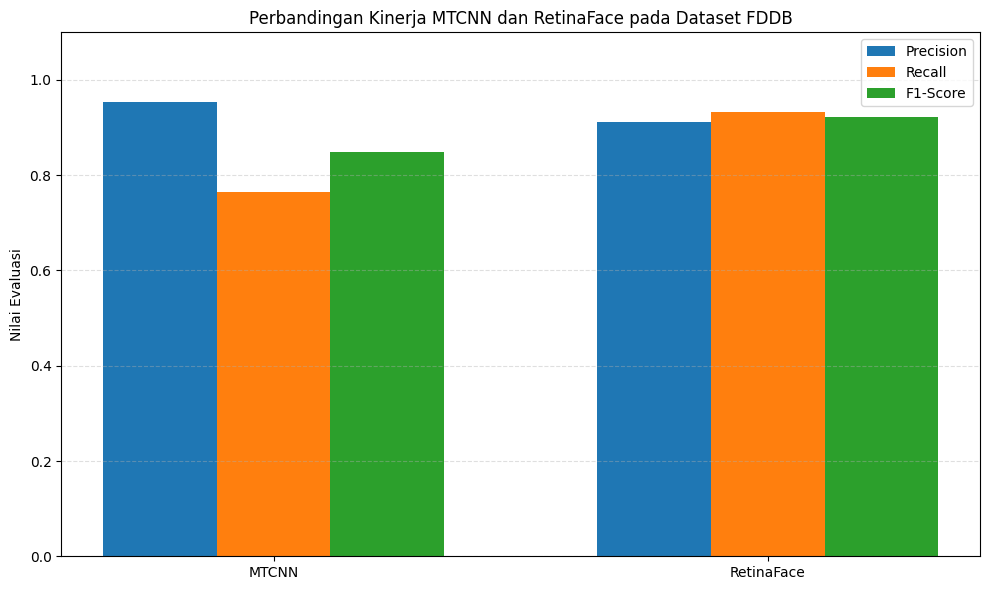

In [93]:
import matplotlib.pyplot as plt
import numpy as np

model = ["MTCNN", "RetinaFace"]

precision = [0.9537, 0.9115]
recall = [0.7652, 0.9337]
f1_score = [0.8491, 0.9224]

x = np.arange(len(model))
width = 0.23

plt.figure(figsize=(10, 6))

plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1_score, width, label="F1-Score")

plt.xticks(x, model)
plt.ylim(0, 1.1)
plt.ylabel("Nilai Evaluasi")
plt.title("Perbandingan Kinerja MTCNN dan RetinaFace pada Dataset FDDB")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("/content/grafik_evaluasi_fddb.png", dpi=300)
plt.show()

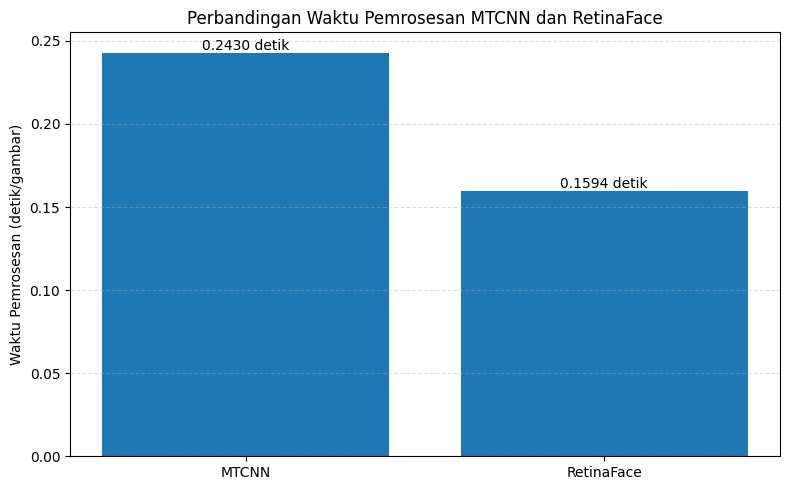

In [94]:
import matplotlib.pyplot as plt

model = ["MTCNN", "RetinaFace"]
waktu = [0.243, 0.1594]

plt.figure(figsize=(8, 5))

bars = plt.bar(model, waktu)

plt.ylabel("Waktu Pemrosesan (detik/gambar)")
plt.title("Perbandingan Waktu Pemrosesan MTCNN dan RetinaFace")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.4f} detik",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("/content/grafik_waktu_fddb.png", dpi=300)
plt.show()

In [95]:
import pandas as pd

hasil_akhir = pd.DataFrame({
    "Model": ["MTCNN", "RetinaFace"],
    "TP": [3957, 4828],
    "FP": [192, 469],
    "FN": [1214, 343],
    "Precision": [0.9537, 0.9115],
    "Recall": [0.7652, 0.9337],
    "F1-Score": [0.8491, 0.9224],
    "Waktu (detik/gambar)": [0.2430, 0.1594]
})

display(hasil_akhir)

hasil_akhir.to_csv(
    "/content/tabel_hasil_akhir_fddb.csv",
    index=False
)

print("Tabel hasil akhir berhasil disimpan!")

,Model,TP,FP,FN,Precision,Recall,F1-Score,Waktu (detik/gambar)
0,MTCNN,3957,192,1214,0.9537,0.7652,0.8491,0.2430
1,RetinaFace,4828,469,343,0.9115,0.9337,0.9224,0.1594


Tabel hasil akhir berhasil disimpan!
